# Image filters and frequency content

How much does smoothing remove noise, and what happens to edges at the same time?

I compare spatial convolution with frequency filtering on a measured image. This gives a reference for the filters that a CNN will later learn.

## Run settings

This experiment runs on CPU with a fixed seed. It compares image operations without training a neural network.

In [3]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import seed_everything

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "01_filters_and_frequency"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Image and corruption

Use the course cameraman image when it has been imported with `prepare_course_data.py`. The built-in scikit-image camera is the fallback. Gaussian noise is added with a fixed seed; clean pixels remain available for a paired evaluation.

In [5]:
import cv2
from skimage import data as sample_images

path = root / "data" / "course" / "cameraman.tif"
image = (
    cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if path.exists()
    else sample_images.camera()
)
clean = image.astype(np.float32) / 255
rng = np.random.default_rng(1031)
noisy = np.clip(clean + rng.normal(0, 0.08, clean.shape), 0, 1).astype(np.float32)
print(clean.shape, clean.min(), clean.max())

(256, 256) 0.02745098 0.99215686


## Spatial filters

The Gaussian kernel is separable. Median filtering is nonlinear and often useful for impulse noise. I keep border reflection identical when comparing OpenCV and PyTorch convolution.

In [7]:
gaussian = cv2.GaussianBlur(noisy, (5, 5), 1.0, borderType=cv2.BORDER_REFLECT_101)
median = cv2.medianBlur((noisy * 255).astype(np.uint8), 5) / 255
kernel_1d = cv2.getGaussianKernel(5, 1).astype(np.float32)
kernel = torch.tensor(kernel_1d @ kernel_1d.T)[None, None]
tensor = torch.tensor(noisy)[None, None]
torch_filtered = F.conv2d(F.pad(tensor, (2, 2, 2, 2), mode="reflect"), kernel)
assert np.allclose(torch_filtered.squeeze().numpy(), gaussian, atol=1e-6)
candidates = {"noisy": noisy, "gaussian": gaussian, "median": median}
table = pd.DataFrame(
    {
        name: {"mse": float(np.mean((value - clean) ** 2))}
        for name, value in candidates.items()
    }
).T
table["psnr_db"] = -10 * np.log10(table.mse)
print(table)

               mse    psnr_db
noisy     0.005917  22.278637
gaussian  0.002955  25.295086
median    0.004491  23.476549


## Gradients

Sobel filters approximate spatial derivatives. Their magnitudes respond to boundaries and noise, so I compare gradients before and after Gaussian smoothing. A larger kernel can improve PSNR while erasing useful boundaries.

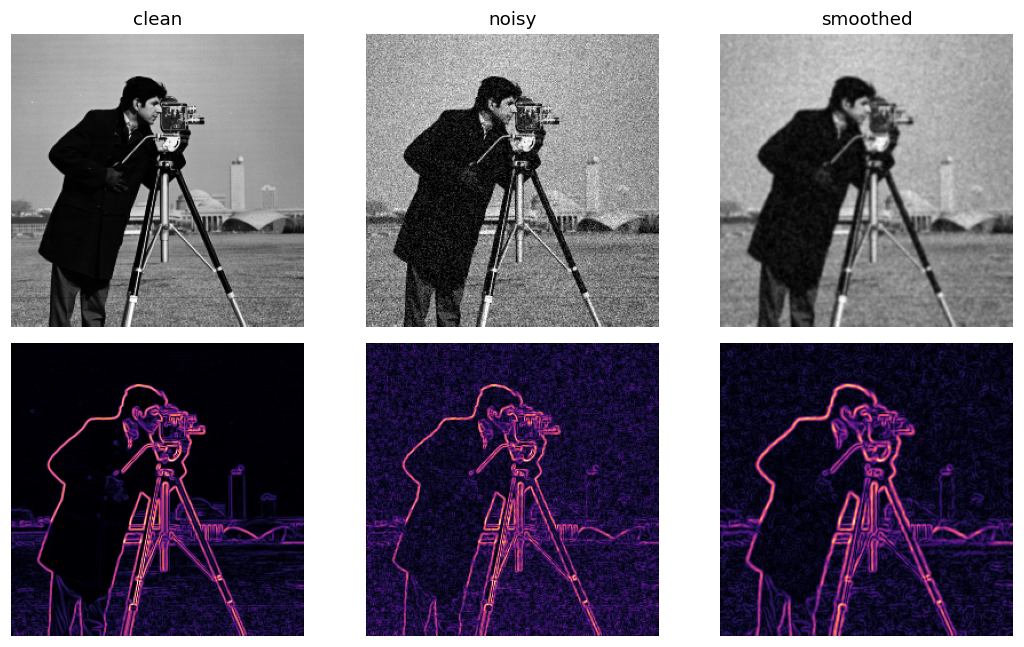

In [9]:
gradients = []
for value in [clean, noisy, gaussian]:
    dx = cv2.Sobel(value, cv2.CV_32F, 1, 0, ksize=3)
    dy = cv2.Sobel(value, cv2.CV_32F, 0, 1, ksize=3)
    gradients.append(np.hypot(dx, dy))
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for axis, value, title in zip(
    axes[0], [clean, noisy, gaussian], ["clean", "noisy", "smoothed"]
):
    axis.imshow(value, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
for axis, value in zip(axes[1], gradients):
    axis.imshow(value, cmap="magma")
    axis.axis("off")
fig.tight_layout()
fig.savefig(output / "filters.png", dpi=140)
plt.show()

## Frequency cutoff

The Fourier transform separates slowly varying intensity from high-frequency detail. A hard circular cutoff has ringing because its spatial impulse response extends beyond a compact neighborhood. The real part of the inverse transform is used after checking the imaginary residue.

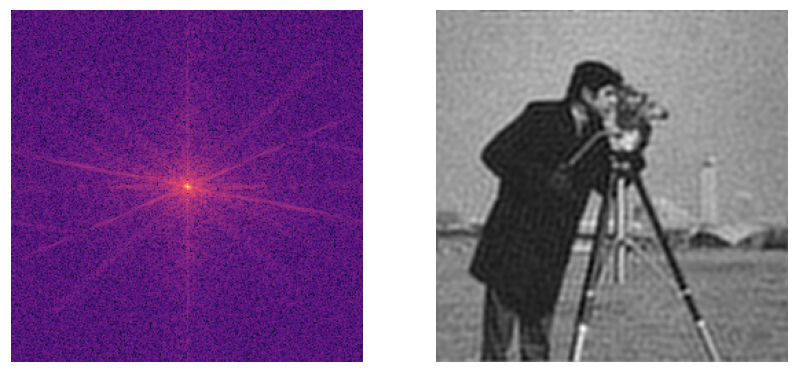

In [11]:
spectrum = np.fft.fftshift(np.fft.fft2(noisy))
rows, columns = np.ogrid[: clean.shape[0], : clean.shape[1]]
radius = np.hypot(rows - clean.shape[0] // 2, columns - clean.shape[1] // 2)
low_pass = spectrum * (radius < 45)
restored_complex = np.fft.ifft2(np.fft.ifftshift(low_pass))
assert np.max(np.abs(restored_complex.imag)) < 1e-6
restored = restored_complex.real
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(np.log1p(np.abs(spectrum)), cmap="magma")
axes[1].imshow(restored, cmap="gray")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
fig.savefig(output / "frequency.png", dpi=140)
plt.show()
results = {
    "spatial": table.to_dict(orient="index"),
    "fft_mse": float(np.mean((restored - clean) ** 2)),
}

## Reading the result

Read MSE together with the gradient images. MSE averages pixel errors and does not identify whether a lost feature was useful for classification. The PyTorch agreement check isolates boundary handling from the mathematical convolution.

Recorded run: Gaussian smoothing increased PSNR from 22.28 to 25.30 dB for the specified Gaussian corruption. The FFT cutoff produced a larger pixel error than that spatial filter. The gradient figure shows the smoothing cost at boundaries.

In [13]:
result_path = root / "results" / "01_filters_and_frequency.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/01_filters_and_frequency.json


## Next experiment

Repeat with salt-and-pepper noise. Choose the noise type before comparing filters, then report both PSNR and the mean gradient error.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [OpenCV filtering](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.